## Test the saved global XGBoost model on the 2026 season
Self-contained: rebuilds the same feature frame as `XGBOOST.ipynb` (no retraining), loads `models/xgb_global.json`, then
1. scores every played 2026 week against ESPN's projections, and
2. predicts games that haven't been played yet (the latest week in `df_2026_final.csv` has projections but no points, so `actual` is NaN).

Re-run the data pipeline to add new weeks to `data/df_2026_final.csv`, then re-run this notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path("../data").resolve()
MODEL_DIR = Path("../models").resolve()
FIG_DIR = Path("../figures").resolve()
FIG_DIR.mkdir(exist_ok=True)
TEST_SEASON = 2026

### Data prep (must match `XGBOOST.ipynb` exactly so the features line up with the trained model)

In [2]:
df_2024 = pd.read_csv(DATA_DIR / "df_2024_final.csv").assign(season=2024)
df_2025 = pd.read_csv(DATA_DIR / "df_2025_final.csv").assign(season=2025)
df_2026 = pd.read_csv(DATA_DIR / "df_2026_final.csv").assign(season=2026)

# make 2026 consistent with 2024/2025 (same columns, order and dtypes)
df_2026 = df_2026.drop(columns=["pro_team_id", "season_type"], errors="ignore")
df_2026 = df_2026.reindex(columns=df_2024.columns)
df_2026 = df_2026.astype(df_2024.dtypes.to_dict(), errors="ignore")

combined = pd.concat([df_2024, df_2025, df_2026], ignore_index=True)

played = combined.loc[(combined["season"] == TEST_SEASON) & combined["fantasy_points"].notna(), "week"]
upcoming = combined.loc[(combined["season"] == TEST_SEASON) & combined["fantasy_points"].isna(), "week"]
print(f"{TEST_SEASON}: played weeks {sorted(played.unique())}, upcoming weeks {sorted(upcoming.unique())}")

2026: played weeks [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)], upcoming weeks [np.int64(10)]


In [3]:
target = "target_next_week_fantasy"

def build_features(combined):
    """Same steps as XGBOOST.ipynb: sort, next-week target/context, cumulative + rolling stats, categoricals."""
    combined = combined.sort_values(['player_id', 'season', 'week']).reset_index(drop=True)

    # next week's target and context (grouped by player AND season)
    g = combined.groupby(['player_id', 'season'])
    combined[target] = g['fantasy_points'].shift(-1)
    combined['next_week_opponent'] = g['opponent'].shift(-1)
    combined['next_week_atVs'] = g['atVs'].shift(-1)
    combined['next_week_projected'] = g['projected_points'].shift(-1)   # ESPN's projection for the game being predicted
    combined['next_week'] = g['week'].shift(-1)                          # week of the next game (skips byes); not a model feature
    for col in ['roof', 'surface', 'temp', 'wind', 'location']:
        combined[f'next_week_{col}'] = g[col].shift(-1)

    # cumulative career / season-to-date means and last-3 rolling means
    stats_to_accumulate = [
        'fantasy_points', 'receptions', 'receivingTargets', 'receivingYards',
        'receivingTouchdowns', 'rushingAttempts', 'rushingYards', 'rushingTouchdowns',
        'completions', 'passingAttempts', 'passingYards', 'passingTouchdowns',
        'interceptions', 'fumblesLost'
    ]
    for col in stats_to_accumulate:
        combined[f'{col}_cum_career_avg'] = combined.groupby('player_id')[col].expanding().mean().values
        combined[f'{col}_season_avg'] = combined.groupby(['player_id', 'season'])[col].expanding().mean().values

    for col in ['fantasy_points', 'receivingTargets', 'rushingAttempts', 'passingAttempts']:
        combined[f'{col}_last3'] = (
            combined.groupby(['player_id', 'season'])[col]
            .transform(lambda s: s.rolling(3, min_periods=1).mean())
        )

    categorical_cols = ['player', 'position', 'next_week_opponent', 'next_week_atVs', 'next_week_surface',
                        'next_week_roof', 'next_week_location']
    for col in categorical_cols:
        if col in combined.columns:
            combined[col] = combined[col].astype('category')
    return combined

frame = build_features(combined)

# the last week of each season has no next game (for 2026 it is the unplayed week)
frame = frame[frame['week'] < frame.groupby('season')['week'].transform('max')].reset_index(drop=True)

/tmp/ipykernel_15978/3229271275.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  combined[f'{col}_cum_career_avg'] = combined.groupby('player_id')[col].expanding().mean().values
/tmp/ipykernel_15978/3229271275.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  combined[f'{col}_season_avg'] = combined.groupby(['player_id', 'season'])[col].expanding().mean().values
/tmp/ipykernel_15978/3229271275.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

### Load the saved models

In [4]:
model = xgb.XGBRegressor()
model.load_model(str(MODEL_DIR / "xgb_global.json"))

groups = {"All": (frame, model)}   # name -> (feature frame, model); kept as a dict so the cells below work unchanged

def features(frame, model):
    """The exact feature columns, in order, that the model was trained on."""
    missing = [c for c in model.get_booster().feature_names if c not in frame.columns]
    if missing:
        raise KeyError(f"Feature frame is missing model features: {missing}")
    return frame[model.get_booster().feature_names]

### SHAP: largest contributing features per model
Mean |SHAP| = how many fantasy points a feature moves a prediction on average (2026 rows). Uses XGBoost's built-in TreeSHAP (`pred_contribs=True`); each row's SHAP values + bias add up to the prediction.

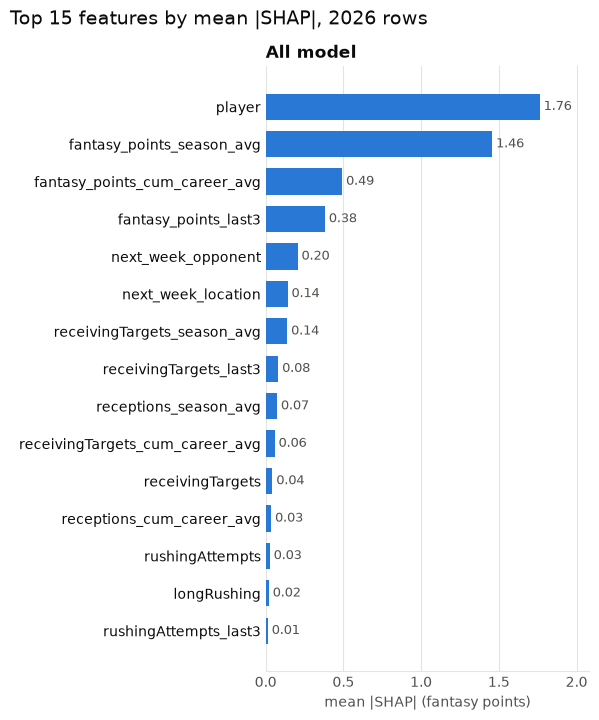

,All
0,player (1.7630000114440918)
1,fantasy_points_season_avg (1.4559999704360962)
2,fantasy_points_cum_career_avg (0.4909999966621...
3,fantasy_points_last3 (0.3799999952316284)
4,next_week_opponent (0.20499999821186066)
5,next_week_location (0.14000000059604645)
6,receivingTargets_season_avg (0.1379999965429306)
7,receivingTargets_last3 (0.07999999821186066)
8,receptions_season_avg (0.07199999690055847)
9,receivingTargets_cum_career_avg (0.05700000002...


In [5]:
TOP_N = 15
EXCLUDE = []        # e.g. ["week"] to hide a feature and rescale the panels

shap_values = {}
for name, (frame, model) in groups.items():
    X = features(frame[frame["season"] == TEST_SEASON], model)
    contribs = model.get_booster().predict(xgb.DMatrix(X, enable_categorical=True), pred_contribs=True)
    sv = pd.DataFrame(contribs[:, :-1], columns=X.columns, index=X.index)   # last column = bias
    sv["bias"] = contribs[:, -1]
    shap_values[name] = sv

importance = {name: sv.drop(columns=["bias", *EXCLUDE], errors="ignore").abs().mean().sort_values(ascending=False)
              for name, sv in shap_values.items()}

BAR, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
fig, axes = plt.subplots(1, len(importance), figsize=(6 * len(importance), 0.38 * TOP_N + 1.6), squeeze=False)
for ax, (name, imp) in zip(axes.ravel(), importance.items()):
    top = imp.head(TOP_N)[::-1]                       # largest at the top
    bars = ax.barh(top.index, top.values, color=BAR, height=0.7)
    for bar, v in zip(bars, top.values):              # value at the end of each bar
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {v:.2f}",
                va="center", ha="left", fontsize=9, color=MUTED)
    ax.set_title(f"{name} model", loc="left", fontsize=12, color=INK, fontweight="bold")
    ax.set_xlabel("mean |SHAP| (fantasy points)", color=MUTED)
    ax.set_xlim(0, top.max() * 1.18)
    ax.tick_params(colors=MUTED, length=0)
    ax.tick_params(axis="y", labelcolor=INK)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
fig.suptitle(f"Top {TOP_N} features by mean |SHAP|, {TEST_SEASON} rows", x=0.01, ha="left",
             fontsize=14, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "shap_top_features_global.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({name: imp.head(TOP_N).round(3).reset_index().apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1)
              for name, imp in importance.items()})

### 1. Evaluate on the played 2026 weeks (model vs ESPN)

In [6]:
def evaluate(frame, model):
    """Model vs ESPN on rows whose next game has been played (and ESPN has a projection)."""
    test = frame[frame["season"] == TEST_SEASON]
    test = test[test[target].notna() & np.isfinite(test[target])]
    X = features(test, model)
    out = test.copy()
    out["model_predicted_score"] = model.predict(X)
    out["actual_score"] = out[target]
    out["espn_projection"] = out["next_week_projected"]
    out["model_error_abs"] = (out["actual_score"] - out["model_predicted_score"]).abs()
    out["espn_error_abs"] = (out["actual_score"] - out["espn_projection"]).abs()
    out = out.dropna(subset=["espn_projection"]).copy()
    out["winner"] = np.select(
        [out["model_error_abs"] < out["espn_error_abs"], out["model_error_abs"] > out["espn_error_abs"]],
        ["Model", "ESPN"], default="Tie")
    for label, pred in [("Model", out["model_predicted_score"]), ("ESPN", out["espn_projection"])]:
        print(f"{label}: MAE={mean_absolute_error(out['actual_score'], pred):.3f}  "
              f"RMSE={np.sqrt(mean_squared_error(out['actual_score'], pred)):.3f}  "
              f"R2={r2_score(out['actual_score'], pred):.3f}")
    return out

results = {}
for name, (fr, mdl) in groups.items():
    print(f"--- {name}")
    results[name] = evaluate(fr, mdl)

all_pos = pd.concat(results.values(), ignore_index=True)
pd.crosstab(all_pos["position"].astype(str), all_pos["winner"], margins=True)

--- All
Model: MAE=4.410  RMSE=5.964  R2=0.408
ESPN: MAE=3.868  RMSE=5.504  R2=0.496


winner,ESPN,Model,All
position,,,
K,111,125,236
QB,178,108,286
RB,430,310,740
TE,495,255,750
WR,684,467,1151
All,1898,1265,3163


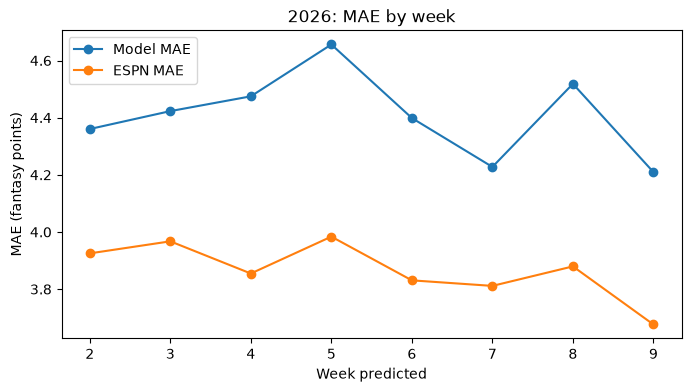

,Model MAE,ESPN MAE
predicted_week,,
2,4.36,3.93
3,4.42,3.97
4,4.47,3.85
5,4.66,3.98
6,4.40,3.83
7,4.23,3.81
8,4.52,3.88
9,4.21,3.68


In [7]:
# MAE by the week being predicted
by_week = (all_pos.groupby(all_pos["next_week"].astype(int).rename("predicted_week"))[["model_error_abs", "espn_error_abs"]].mean()
           .rename(columns={"model_error_abs": "Model MAE", "espn_error_abs": "ESPN MAE"}))
ax = by_week.plot(marker="o", figsize=(8, 4), title=f"{TEST_SEASON}: MAE by week")
ax.set_xlabel("Week predicted"); ax.set_ylabel("MAE (fantasy points)")
plt.show()
by_week.round(2)

### 2. Predict a player / an upcoming week

In [8]:
def _predict(rows, model):
    return pd.DataFrame({
        "player": rows["player"].astype(str), "position": rows["position"].astype(str),
        "team": rows["team"].astype(str),
        "predicted_week": rows["next_week"].astype(int),
        "opponent": rows["next_week_opponent"].astype(str),
        "model_prediction": model.predict(features(rows, model)).round(2),
        "espn_projected": rows["next_week_projected"].round(2),
        "actual": rows[target],                        # NaN for games not played yet
    })

def predict_player(name, season=TEST_SEASON, week=None):
    """Predict a player's fantasy points with the global model.
    week = the week to predict (uses stats from the player's previous game); None = every week available."""
    found = frame[frame["player"].str.contains(name, case=False, na=False, regex=False) & (frame["season"] == season)]
    players = found["player"].unique()
    if len(players) != 1:
        print(f"'{name}' matches {list(players) if len(players) else 'no players'} in {season}.")
        return None

    player = players[0]
    fr, mdl = groups["All"]
    rows = fr[(fr["player"] == player) & (fr["season"] == season) & fr["next_week"].notna()]
    if week is not None:
        rows = rows[rows["next_week"] == week]
    if rows.empty:
        print(f"No feature rows for {player} to predict week {week}.")
        return None
    return _predict(rows, mdl).reset_index(drop=True)

def predict_week(week, season=TEST_SEASON, position=None):
    """Predictions for every player whose next game is in `week` (works for unplayed weeks), best first."""
    out = [_predict(rows, model)
           for frame, model in groups.values()
           if not (rows := frame[(frame["season"] == season) & (frame["next_week"] == week)]).empty]
    out = pd.concat(out, ignore_index=True).sort_values("model_prediction", ascending=False)
    if position is not None:
        out = out[out["position"] == position]
    return out.reset_index(drop=True)

next_week = int(upcoming.max()) if len(upcoming) else int(played.max())   # first unplayed week
print(f"Predicting week {next_week} of {TEST_SEASON}")

Predicting week 10 of 2026


In [9]:
predict_player("Christian McCaffrey")              # every 2026 week; the last row is the unplayed week
# predict_player("Josh Allen", week=next_week)

,player,position,team,predicted_week,opponent,model_prediction,espn_projected,actual
0,Christian McCaffrey,RB,SF,2,MIA,17.799999,21.48,22.6
1,Christian McCaffrey,RB,SF,3,ARI,17.270000,20.90,21.6
2,Christian McCaffrey,RB,SF,4,DEN,16.719999,20.26,16.0
3,Christian McCaffrey,RB,SF,5,SEA,16.760000,18.72,17.3
4,Christian McCaffrey,RB,SF,6,WSH,19.250000,21.22,30.7
5,Christian McCaffrey,RB,SF,7,ATL,20.280001,21.92,22.0
6,Christian McCaffrey,RB,SF,9,LV,18.170000,21.98,22.7
7,Christian McCaffrey,RB,SF,10,DAL,20.650000,21.75,NaN


In [10]:
predict_week(next_week).head(25)                # top projected players for the upcoming week
# predict_week(next_week, position="QB")

,player,position,team,predicted_week,opponent,model_prediction,espn_projected,actual
0,Christian McCaffrey,RB,SF,10,DAL,20.650000,21.75,NaN
1,Ja'Marr Chase,WR,CIN,10,PIT,20.139999,22.92,NaN
2,Jonathan Taylor,RB,IND,10,MIA,19.860001,17.85,NaN
3,Lamar Jackson,QB,BAL,10,LAC,19.709999,0.00,NaN
4,Joe Burrow,QB,CIN,10,PIT,19.290001,19.03,NaN
5,Brock Purdy,QB,SF,10,DAL,18.309999,20.73,NaN
6,Jaxson Dart,QB,NYG,10,WSH,18.299999,0.00,NaN
7,Patrick Mahomes,QB,KC,10,ATL,17.709999,17.52,NaN
8,Jayden Daniels,QB,WSH,10,NYG,17.209999,17.67,NaN
9,Dak Prescott,QB,DAL,10,SF,17.059999,16.55,NaN
